**1. Setup.**
Mount Google Drive, import libraries, and set the folder paths and random seed used by every later cell. Raw files are read from Raw Data; everything this notebook produces is saved to processed.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os
import numpy as np
import pandas as pd
RAW = "/content/drive/MyDrive/BT4222_Group10_JDSearch/Raw Data"
OUT = "/content/drive/MyDrive/BT4222_Group10_JDSearch/processed"
os.makedirs(OUT, exist_ok=True)
SEED = 4222
print(os.listdir(RAW))


Mounted at /content/drive
['product_meta_data.txt', 'user_behavior_data.txt']


**2. Look at one raw row.** Before writing any parsing code, print the first row of user_behavior_data.txt to see how it's stored: 7 tab-separated columns, list items separated by _, and tokens inside text separated by a hidden \x18. Check: the four history lists have the same length, and history_time_list has one extra value (the gap from the last action to the search).

In [ ]:
with open(f"{RAW}/user_behavior_data.txt") as f:
    header = f.readline().rstrip("\n").split("\t")
    row = f.readline().rstrip("\n").split("\t")

for name, value in zip(header, row):
    print(f"{name:22s} {len(value.split('_')):4d} items | {value[:60]}")


query                     1 items | 63995226602574196100244625575117
candidate_wid_list       90 items | 36098226_17729172_34921664_68317377_693764_36024150_84225794
candidate_label_list     90 items | 1.0_0.0_0.0_0.0_0.0_0.0_0.0_0.0_0.0_0.0_0.0_0.0_0.0_0.0_0.0_
history_qry_list        182 items | -1_-1_-1_68784030_36547097602574193663289_959229139842363
history_wid_list        182 items | 9227588_52788392_4585436_87422901_57364733_21056095_62869065
history_type_list       182 items | ORD_ORD_CART_CART_CART_CART_CART_CART_CART_CART_CART_CART_CA
history_time_list       183 items | 0_0_22967659_82448_432_10315_51_188_51_254173_182238_72_37_5


**3a. Parse one row.** Turn one row into what we need: the labels of the shown products, the history action types, the gaps, and each action's age, meaning how many seconds before the search it happened (the sum of all later gaps). We test this on one row before looping over all 173,831.

In [ ]:
TYPE = {"CLICK": 0, "CART": 1, "ORD": 2, "FLW": 3}

cols   = row                                              # one raw row, split on tabs
labels = [int(float(x)) for x in cols[2].split("_")]      # candidate labels, 0-3
types  = [TYPE[t] for t in cols[5].split("_")]            # history actions, oldest first
tm     = np.array(cols[6].split("_"), dtype=np.int64)     # gaps in seconds, one extra
age    = np.cumsum(tm[::-1])[::-1][1:]                    # seconds before the search, one per action
print("candidate labels          :", len(labels))
print("history actions           :", len(types))
print("time gaps (one extra)     :", len(tm))
print("ages of 3 oldest actions  :", age[:3], "seconds")
print("ages of 3 newest actions  :", age[-3:], "seconds")
print("same in days (oldest)     :", np.round(age[:3] / 86400, 2))
print("same in days (newest)     :", np.round(age[-3:] / 86400, 2))

candidate labels          : 90
history actions           : 182
time gaps (one extra)     : 183
ages of 3 oldest actions  : [30299133 30299133  7331474] seconds
ages of 3 newest actions  : [175774 175679 175658] seconds
same in days (oldest)     : [350.68 350.68  84.86]
same in days (newest)     : [2.03 2.03 2.03]


**3b. Table layouts.** Declare the columns and number types of each table up front. Small types (int8 for labels and action types, int32 for IDs) keep memory low, and parquet stores them exactly.

In [ ]:
import pyarrow as pa
import pyarrow.parquet as pq

SCHEMAS = {
    "searches":  pa.schema([("sid", pa.int32()), ("query", pa.string()), ("n_cands", pa.int16()),
                            ("n_pos", pa.int16()), ("hist_len", pa.int32())]),
    "exposures": pa.schema([("sid", pa.int32()), ("orig_idx", pa.int16()), ("wid", pa.int32()),
                            ("label", pa.int8())]),
    "history":   pa.schema([("sid", pa.int32()), ("idx", pa.int32()), ("wid", pa.int32()),
                            ("type", pa.int8()), ("gap_s", pa.int32()), ("age_s", pa.int32()),
                            ("qry", pa.string())]),
}

**3c. Parse all the rows.**

In [ ]:
CHUNK = 20_000                                            # rows per batch written to disk
writers = {name: pq.ParquetWriter(f"{OUT}/{name}.parquet", schema) for name, schema in SCHEMAS.items()}
buf = {name: {col: [] for col in schema.names} for name, schema in SCHEMAS.items()}

def flush():
    """Write whatever is in the buffers to the three files, then empty the buffers."""
    for name, schema in SCHEMAS.items():
        if buf[name]["sid"]:
            table = pa.table({c: pa.array(v, type=schema.field(c).type) for c, v in buf[name].items()},
                             schema=schema)
            writers[name].write_table(table)
            for v in buf[name].values():
                v.clear()

with open(f"{RAW}/user_behavior_data.txt") as f:
    f.readline()
    for sid, line in enumerate(f):
        cols   = line.rstrip("\n").split("\t")
        cands  = cols[1].split("_")
        labels = [int(float(x)) for x in cols[2].split("_")]
        hq, hw, ht = cols[3].split("_"), cols[4].split("_"), cols[5].split("_")
        tm     = np.array(cols[6].split("_"), dtype=np.int64)
        age    = np.cumsum(tm[::-1])[::-1][1:]
        n      = len(hw)                                  # number of past actions

        s = buf["searches"]                               # one row for this search
        s["sid"].append(sid);               s["query"].append(cols[0])
        s["n_cands"].append(len(cands));    s["n_pos"].append(sum(l > 0 for l in labels))
        s["hist_len"].append(n)

        e = buf["exposures"]                              # one row per shown product
        e["sid"].extend([sid] * len(cands)); e["orig_idx"].extend(range(len(cands)))
        e["wid"].extend(int(w) for w in cands); e["label"].extend(labels)

        h = buf["history"]                                # one row per past action
        h["sid"].extend([sid] * n);          h["idx"].extend(range(n))
        h["wid"].extend(int(w) for w in hw); h["type"].extend(TYPE[t] for t in ht)
        h["gap_s"].extend(tm[:n].tolist());  h["age_s"].extend(age.tolist())
        h["qry"].extend(None if q == "-1" else q for q in hq)   # -1 means no search: store as missing

        if (sid + 1) % CHUNK == 0:
            flush()
            print(f"{sid + 1:,} rows done")

flush()
for w in writers.values():
    w.close()

20,000 rows done
40,000 rows done
60,000 rows done
80,000 rows done
100,000 rows done
120,000 rows done
140,000 rows done
160,000 rows done


**3d. Checking the table.**

In [ ]:
searches  = pd.read_parquet(f"{OUT}/searches.parquet")
exposures = pd.read_parquet(f"{OUT}/exposures.parquet", columns=["label"])
history   = pd.read_parquet(f"{OUT}/history.parquet", columns=["type"])
print("searches            :", f"{len(searches):,}", "| with no positive label:", f"{(searches.n_pos == 0).sum():,}")
print("exposures           :", f"{len(exposures):,}")
print("  labels 0/1/2/3    :", exposures.label.value_counts().sort_index().tolist())
print("history actions     :", f"{len(history):,}")
print("  CLICK/CART/ORD/FLW:", history.type.value_counts().sort_index().tolist())

searches            : 173,831 | with no positive label: 2,103
exposures           : 15,510,012
  labels 0/1/2/3    : [15189116, 224487, 75573, 20836]
history actions     : 26,667,260
  CLICK/CART/ORD/FLW: [8298894, 11526504, 6817283, 24579]


**4a. Check how the shown products are ordered.**

In [ ]:
ex = pd.read_parquet(f"{OUT}/exposures.parquet", columns=["sid", "orig_idx", "label"])
print("search 0, labels in original order:", ex[ex.sid == 0].label.head(12).tolist())

last_pos  = ex[ex.label > 0].groupby("sid").orig_idx.max()     # position of the LAST positive in each list
first_neg = ex[ex.label == 0].groupby("sid").orig_idx.min()    # position of the FIRST negative in each list
both = last_pos.index.intersection(first_neg.index)            # lists that contain both kinds
violations = (last_pos[both] > first_neg[both]).sum()

print("lists with both positives and negatives        :", f"{len(both):,}")
print("lists where a negative comes before a positive :", violations)


search 0, labels in original order: [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
lists with both positives and negatives        : 171,175
lists where a negative comes before a positive : 0


**Finding: the list order gives away the labels.** In all 171,175 searches that contain both interacted and ignored products, every interacted product comes before every ignored one, with 0 exceptions. Search 0 shows the pattern: its clicked product is at position 0. Position is effectively the answer key, so it must never reach the model. Section 6 shuffles every list and deletes orig_idx.

**4b. Check how far back each action type goes.** Using each action's age, find the oldest action of each type and count how many fall past 7, 90 and 365 days. Then count actions per day around each cutoff to see where each type stops.

In [ ]:
hist = pd.read_parquet(f"{OUT}/history.parquet", columns=["type", "age_s"])
NAMES = {0: "CLICK", 1: "CART", 2: "ORD", 3: "FLW"}
hist["age_d"] = hist.age_s / 86400                              # seconds -> days

for code, name in NAMES.items():
    a = hist.age_d[hist.type == code]
    print(f"{name:5s} n={len(a):>10,} | oldest {a.max():7.2f} d | older than 7 d: {(a > 7).sum():>10,}"
          f" | older than 90 d: {(a > 90).sum():>9,} | older than 365 d: {(a > 365).sum()}")

hist["day"] = (hist.age_s // 86400).astype(int)                 # whole days before the search
per_day = pd.crosstab(hist.day, hist.type.map(NAMES))           # table: day x action type -> count

def show(name, days):
    counts = per_day[name].reindex(days, fill_value=0)          # days with no actions show as 0
    print(f"{name:5s} " + "  ".join(f"day {d}: {c:,}" for d, c in counts.items()))

show("CLICK", range(4, 9))
show("CART", range(87, 92))
show("ORD", range(361, 367))

CLICK n= 8,298,894 | oldest   13.15 d | older than 7 d:        107 | older than 90 d:         0 | older than 365 d: 0
CART  n=11,526,504 | oldest  635.29 d | older than 7 d: 10,191,343 | older than 90 d:     1,204 | older than 365 d: 1
ORD   n= 6,817,283 | oldest  364.99 d | older than 7 d:  6,614,460 | older than 90 d: 4,781,358 | older than 365 d: 0
FLW   n=    24,579 | oldest   89.99 d | older than 7 d:     21,928 | older than 90 d:         0 | older than 365 d: 0
CLICK day 4: 1,111,199  day 5: 1,068,745  day 6: 520,760  day 7: 5  day 8: 32
CART  day 87: 96,921  day 88: 96,444  day 89: 49,779  day 90: 365  day 91: 207
ORD   day 361: 16,122  day 362: 12,833  day 363: 12,529  day 364: 6,711  day 365: 0  day 366: 0


**4c. Plot actions per day by type.**

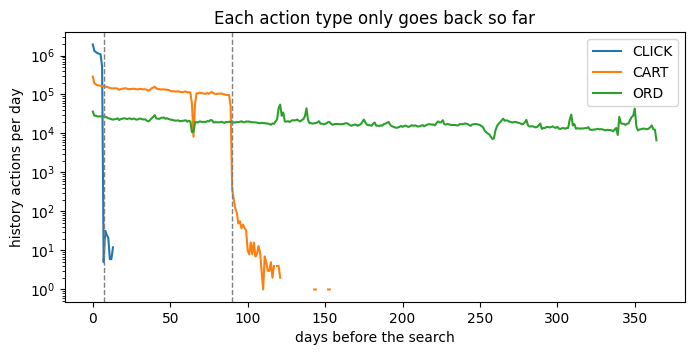

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 3.5))
for name in ["CLICK", "CART", "ORD"]:
  y = per_day[name].reindex(range(365), fill_value=0).replace(0, np.nan)
  ax.plot(y.index, y.values, label=name, linewidth=1.5)
for x in (7, 90):
    ax.axvline(x, color="grey", linestyle="--", linewidth=1)
ax.set_yscale("log")
ax.set_xlabel("days before the search")
ax.set_ylabel("history actions per day")
ax.set_title("Each action type only goes back so far")
ax.legend()
plt.show()

**5a. Which products were shown in a search.**

In [ ]:
import pyarrow as pa
import pyarrow.parquet as pq

shown = set(pd.read_parquet(f"{OUT}/exposures.parquet", columns=["wid"]).wid.unique().tolist())
print(f"distinct products shown in searches: {len(shown):,}")

distinct products shown in searches: 8,362,535


**5b. Table layouts**

In [ ]:
PROD_SCHEMA = pa.schema([("wid", pa.int32()), ("brand_id", pa.int32()),
                         ("cate_id_1", pa.int32()), ("cate_id_2", pa.int32()),
                         ("cate_id_3", pa.int32()), ("cate_id_4", pa.int32()),
                         ("shop_id", pa.int32()), ("title_len", pa.int16())])
TITLE_SCHEMA = pa.schema([("wid", pa.int32()), ("title", pa.string())])


**5c. Stream the catalogue**

In [ ]:
CHUNK = 200_000
w_prod  = pq.ParquetWriter(f"{OUT}/products.parquet", PROD_SCHEMA, compression="zstd")
w_title = pq.ParquetWriter(f"{OUT}/titles.parquet",   TITLE_SCHEMA, compression="zstd")
P = {c: [] for c in PROD_SCHEMA.names}
T = {c: [] for c in TITLE_SCHEMA.names}

def flush_products():
    """Write the buffered rows of both tables to disk, then empty the buffers."""
    for writer, schema, b in ((w_prod, PROD_SCHEMA, P), (w_title, TITLE_SCHEMA, T)):
        if b["wid"]:
            writer.write_table(pa.table({c: pa.array(v, type=schema.field(c).type) for c, v in b.items()},
                                        schema=schema))
            for v in b.values():
                v.clear()

n_rows = n_bad = 0
with open(f"{RAW}/product_meta_data.txt") as f:
    f.readline()                                          # skip the header
    for line in f:
        p = line.rstrip("\n").split("\t")                 # 13 columns
        if len(p) < 13:                                   # guard against a broken line
            n_bad += 1
            continue
        wid, shop = int(p[0]), int(p[12])
        P["wid"].append(wid);               P["brand_id"].append(int(p[2]))
        P["cate_id_1"].append(int(p[4]));   P["cate_id_2"].append(int(p[6]))
        P["cate_id_3"].append(int(p[8]));   P["cate_id_4"].append(int(p[10]))
        P["shop_id"].append(None if shop == -1 else shop)  # -1 = unknown shop: store as missing
        P["title_len"].append(p[1].count("\x18") + 1)       # tokens = separators + 1
        if wid in shown:                                    # keep titles only for shown products
            T["wid"].append(wid);           T["title"].append(p[1])
        n_rows += 1
        if n_rows % CHUNK == 0:
            flush_products()
        if n_rows % 2_000_000 == 0:
            print(f"{n_rows:,} catalogue rows done")

flush_products()                                          # the last partial chunk
w_prod.close(); w_title.close()
print(f"done: {n_rows:,} rows | skipped broken lines: {n_bad}")


2,000,000 catalogue rows done
4,000,000 catalogue rows done
6,000,000 catalogue rows done
8,000,000 catalogue rows done
10,000,000 catalogue rows done
12,000,000 catalogue rows done
done: 12,141,247 rows | skipped broken lines: 0


**5d. Check against the known numbers.**

In [ ]:
prods  = pd.read_parquet(f"{OUT}/products.parquet")
titles = pd.read_parquet(f"{OUT}/titles.parquet", columns=["wid"])
ex_wid = pd.read_parquet(f"{OUT}/exposures.parquet", columns=["wid"]).wid
print("products                 :", f"{len(prods):,}", "| each product once:", prods.wid.is_unique)
print("missing shop             :", f"{prods.shop_id.isna().sum():,}")
print("distinct brand / c1 / c2 / c3 / c4 / shop:",
      [int(prods[c].nunique()) for c in ["brand_id", "cate_id_1", "cate_id_2", "cate_id_3", "cate_id_4", "shop_id"]])
print("title length min/median/mean/max:", prods.title_len.min(), int(prods.title_len.median()),
      round(prods.title_len.mean(), 3), prods.title_len.max())
print("shown products with a title   :", f"{len(titles):,} of {len(shown):,}")
print("exposures with a catalogue row:", f"{ex_wid.isin(prods.wid).mean():.2%}")


products                 : 12,141,247 | each product once: True
missing shop             : 103,162
distinct brand / c1 / c2 / c3 / c4 / shop: [182585, 76, 671, 5819, 7137, 250934]
title length min/median/mean/max: 1 27 27.913 78
shown products with a title   : 8,305,622 of 8,362,535
exposures with a catalogue row: 99.55%


**6. Train/validation/test split and shuffled lists.** Each user has exactly one search, so splitting searches is the same as splitting users.

**6a. Split the searches.**

In [ ]:
from sklearn.model_selection import train_test_split

SPLIT = {"train": 0, "val": 1, "test": 2}                        # -1 = excluded (no interaction)
searches = pd.read_parquet(f"{OUT}/searches.parquet")
eligible = searches.sid[searches.n_pos > 0].to_numpy()           # searches with at least one interaction

train_ids, temp_ids = train_test_split(eligible, test_size=0.3, random_state=SEED)   # 70% / 30%
val_ids, test_ids   = train_test_split(temp_ids, test_size=0.5, random_state=SEED)   # 30% -> 15% / 15%

split = np.full(len(searches), -1, dtype=np.int8)                # start with everyone "excluded"
split[train_ids] = SPLIT["train"]
split[val_ids]   = SPLIT["val"]
split[test_ids]  = SPLIT["test"]
searches["split"] = split

print("searches per split:", {name: int((split == code).sum()) for name, code in SPLIT.items()},
      "| excluded:", int((split == -1).sum()))
print("test-set fingerprint (sum of test sids):", int(test_ids.astype(np.int64).sum()),
      "| first 5 test sids:", [int(x) for x in sorted(test_ids)[:5]])


searches per split: {'train': 120209, 'val': 25759, 'test': 25760} | excluded: 2103
test-set fingerprint (sum of test sids): 2240481275 | first 5 test sids: [9, 38, 41, 49, 52]


**6b. Shuffle every list, delete orig_idx and attach the train/val/test split to each row.**

In [ ]:
ex = pd.read_parquet(f"{OUT}/exposures.parquet")                 # sid, orig_idx, wid, label
rng = np.random.default_rng(SEED)
ex["shuffle_key"] = rng.random(len(ex))                          # a random number for every shown product
ex = ex.sort_values(["sid", "shuffle_key"])                      # keep searches together, random order inside each
ex = ex.drop(columns=["orig_idx", "shuffle_key"]).reset_index(drop=True)
ex["split"] = split[ex.sid.to_numpy()]                           # each row takes its search's split

print("exposures columns now:", list(ex.columns))
for name, code in SPLIT.items():
    lab = ex.label[ex.split == code]
    print(f"  {name:5s}: {len(lab):>10,} exposures | positive rate {(lab > 0).mean():.2%}")

exposures columns now: ['sid', 'wid', 'label', 'split']
  train: 10,743,610 exposures | positive rate 2.09%
  val  :  2,303,929 exposures | positive rate 2.08%
  test :  2,301,178 exposures | positive rate 2.09%


**6c. Check the shuffling works as intended.**

In [ ]:
pos_in_list = ex.groupby("sid").cumcount()                       # new position 0, 1, 2, ... in each list
first = ex[pos_in_list == 0]
print("share of lists whose FIRST product is a positive:", f"{(first.label > 0).mean():.1%}  (was 98.8% before shuffling)")

last_pos  = ex[ex.label > 0].assign(p=pos_in_list).groupby("sid").p.max()
first_neg = ex[ex.label == 0].assign(p=pos_in_list).groupby("sid").p.min()
both = last_pos.index.intersection(first_neg.index)
print("lists where a negative now comes before a positive:", f"{(last_pos[both] > first_neg[both]).sum():,} of {len(both):,}")

share of lists whose FIRST product is a positive: 3.1%  (was 98.8% before shuffling)
lists where a negative now comes before a positive: 168,915 of 171,175


**6d. Save.**

In [ ]:
searches.to_parquet(f"{OUT}/searches.parquet", index=False, compression="zstd")
ex.to_parquet(f"{OUT}/exposures.parquet", index=False, compression="zstd")
print("saved")

saved


**7a. Print the numbers.**

In [ ]:
import os, json
import pyarrow.parquet as pq

TABLES = ["searches", "exposures", "history", "products", "titles"]
for name in TABLES:
    path = f"{OUT}/{name}.parquet"
    rows = pq.ParquetFile(path).metadata.num_rows                          # row count, without loading the data
    cols = ", ".join(f"{f.name} ({f.type})" for f in pq.read_schema(path))  # column names and types
    print(f"{name:9s} {rows:>11,} rows | {os.path.getsize(path) / 1e6:6.0f} MB | {cols}")

searches      173,831 rows |      3 MB | sid (int32), query (string), n_cands (int16), n_pos (int16), hist_len (int32), split (int8)
exposures  15,510,012 rows |     68 MB | sid (int32), wid (int32), label (int8), split (int8)
history    26,667,260 rows |    421 MB | sid (int32), idx (int32), wid (int32), type (int8), gap_s (int32), age_s (int32), qry (string)
products   12,141,247 rows |    215 MB | wid (int32), brand_id (int32), cate_id_1 (int32), cate_id_2 (int32), cate_id_3 (int32), cate_id_4 (int32), shop_id (int32), title_len (int16)
titles      8,305,622 rows |    725 MB | wid (int32), title (string)


**7b. Cross check.**

In [ ]:
s = pd.read_parquet(f"{OUT}/searches.parquet", columns=["sid", "n_cands", "hist_len", "split"])
e = pd.read_parquet(f"{OUT}/exposures.parquet", columns=["sid", "split"])
h = pd.read_parquet(f"{OUT}/history.parquet", columns=["sid"])
n_exp  = e.groupby("sid").size().reindex(s.sid, fill_value=0).to_numpy()   # products shown per search
n_hist = h.groupby("sid").size().reindex(s.sid, fill_value=0).to_numpy()   # past actions per search

checks = {
    "sid runs 0, 1, 2, ... with no gaps":     bool((s.sid.to_numpy() == np.arange(len(s))).all()),
    "exposures per search = n_cands":         bool((n_exp == s.n_cands.to_numpy()).all()),
    "history actions per search = hist_len":  bool((n_hist == s.hist_len.to_numpy()).all()),
    "every exposure has its search's split":  bool((e.split.to_numpy() == s.split.to_numpy()[e.sid.to_numpy()]).all()),
    "orig_idx is gone from exposures":        "orig_idx" not in pq.read_schema(f"{OUT}/exposures.parquet").names,
}
for name, ok in checks.items():
    print(f"  {'PASS' if ok else 'FAIL'}  {name}")

  PASS  sid runs 0, 1, 2, ... with no gaps
  PASS  exposures per search = n_cands
  PASS  history actions per search = hist_len
  PASS  every exposure has its search's split
  PASS  orig_idx is gone from exposures


**7c. Save.**

In [ ]:
meta = {
    "seed": SEED,
    "type_codes":  {"CLICK": 0, "CART": 1, "ORD": 2, "FLW": 3},
    "label_codes": {"none": 0, "click": 1, "cart": 2, "order": 3},
    "split_codes": {"train": 0, "val": 1, "test": 2, "excluded": -1},
    "window_days": {"CLICK": 7, "CART": 90, "FLW": 90, "ORD": 365},
    "split_sizes": {k: int((s.split == v).sum()) for k, v in {"train": 0, "val": 1, "test": 2, "excluded": -1}.items()},
    "table_rows":  {name: pq.ParquetFile(f"{OUT}/{name}.parquet").metadata.num_rows for name in TABLES},
}
with open(f"{OUT}/meta.json", "w") as f:
    json.dump(meta, f, indent=2)
print("saved meta.json:", json.dumps(meta["split_sizes"]))

saved meta.json: {"train": 120209, "val": 25759, "test": 25760, "excluded": 2103}
